# Electrode Geometries & Concentration Profiles (`softpotato.geometry`)

## 1. Goal

Use `PlanarGeometry`, `CylindricalGeometry`, and `SphericalGeometry` directly inside `DiffusionProblem` to solve radial/linear diffusion, visualize 2D concentration profiles $c(r, t)$, and benchmark transient currents against analytical Cottrell equations.

## 2. Geometry Operators & Surface Areas

Each `Geometry` subclass encapsulates the coordinate metric $p \in \{0, 1, 2\}$ in the Laplacian:

$$
\nabla^2 c = \frac{\partial^2 c}{\partial r^2} + \frac{p}{r}\frac{\partial c}{\partial r}
$$

as well as `area` and `surface_flux()`.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato import analytical as spa
from softpotato.geometry import CylindricalGeometry, PlanarGeometry, SphericalGeometry
from softpotato.grid import GeometricExpandingMesh
from softpotato.solver import DiffusionProblem, DirichletBC, get_solver

r0 = 25.0e-6       # 25 um radius
length = 1.0e-3    # 1 mm cylinder length
D = 1.0e-9
c_bulk = 1.0
n = 1
t_max = 2.0

planar = PlanarGeometry(area=np.pi * r0**2)
cylinder = CylindricalGeometry(r0=r0, length=length)
sphere = SphericalGeometry(r0=r0, hemisphere=False)

for name, geom in [("Planar", planar), ("Cylindrical", cylinder), ("Spherical", sphere)]:
    print(f"{name:<12s} | area = {geom.area:.3e} m^2")

Planar       | area = 1.963e-09 m^2
Cylindrical  | area = 1.571e-07 m^2
Spherical    | area = 7.854e-09 m^2


## 3. Solving Potential-Step Diffusion Across Geometries

We apply a diffusion-limited Dirichlet boundary condition $c(r_0, t) = 0$ at the electrode surface and $c(r_{\max}, t) = c_{\text{bulk}}$ in the bulk, using a `GeometricExpandingMesh` that starts at $r_0$ (or $0$ for planar).

In [2]:
t_eval = np.linspace(0.02, t_max, 60)
delta = 8.0 * np.sqrt(D * t_max)
solver = get_solver("scipy_ivp", method="BDF", rtol=1e-7, atol=1e-9)

sims = {}
for name, geom, x_min in [
    ("Planar", planar, 0.0),
    ("Cylindrical", cylinder, r0),
    ("Spherical", sphere, r0),
]:
    mesh = GeometricExpandingMesh.from_diffusion_layer(
        D=D, t_max=t_max, x_min=x_min, factor=8.0, n_points=80, gamma=1.07
    )
    prob = DiffusionProblem(
        grid=mesh,
        diffusivity={"Ox": D},
        boundary_conditions={"Ox": (DirichletBC(0.0), DirichletBC(c_bulk))},
        initial_conditions={"Ox": c_bulk},
        geometry=geom,
        n_electrons={"Ox": n},
    )
    res = solver.solve(prob, t_span=(0.0, t_max), t_eval=t_eval)
    sims[name] = (mesh, geom, res)
    print(f"{name:<12s} | success={res.success} | final I = {abs(res.currents['Ox'][-1])*1e9:.3f} nA")

Planar       | success=True | final I = 2.391 nA


Cylindrical  | success=True | final I = 427.318 nA
Spherical    | success=True | final I = 39.956 nA


## 4. Concentration Profiles & Analytical Current Comparison

We visualize $c_{\text{Ox}}(r, t)$ snapshots and heatmaps, and compare the simulated current densities against `spa.cottrell()`, `spa.cottrell_cylinder()`, and `spa.cottrell_spherical()`.

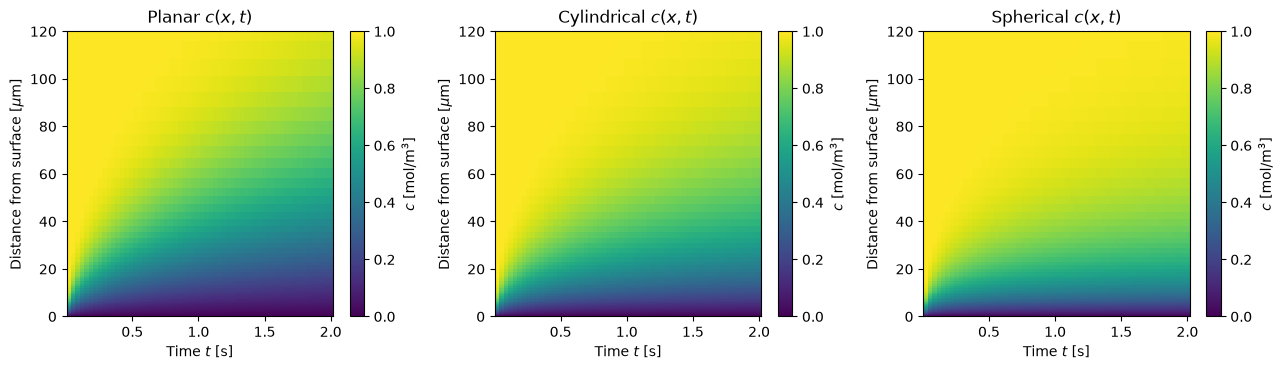

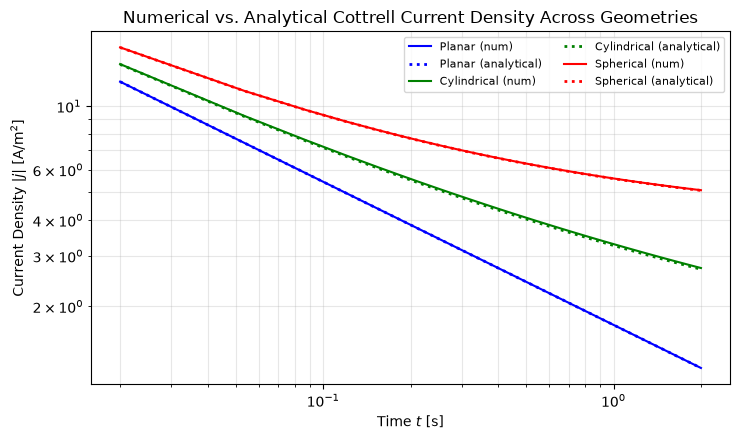

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, (mesh, geom, res)) in zip(axes, sims.items()):
    dist_um = (mesh.nodes - mesh.nodes[0]) * 1e6
    c_mat = res.concentrations["Ox"]
    im = ax.pcolormesh(t_eval, dist_um, c_mat.T, shading="auto", cmap="viridis")
    ax.set_ylim(0, 120)
    ax.set_xlabel("Time $t$ [s]")
    ax.set_ylabel(r"Distance from surface [$\mu$m]")
    ax.set_title(f"{name} $c(x, t)$")
    fig.colorbar(im, ax=ax, label=r"$c$ [$\mathrm{mol/m^3}$]")
fig.tight_layout()
plt.show()

# Compare current density j = |I| / A against analytical Cottrell formulas
fig, ax = plt.subplots(figsize=(7.5, 4.5))
j_plan_num = np.abs(sims["Planar"][2].currents["Ox"]) / planar.area
j_plan_ana = spa.cottrell(t_eval, n=n, D=D, c_bulk=c_bulk, area=1.0)

j_cyl_num = np.abs(sims["Cylindrical"][2].currents["Ox"]) / cylinder.area
j_cyl_ana = spa.cottrell_cylinder(t_eval, r0=r0, n=n, D=D, c_bulk=c_bulk, length=length) / cylinder.area

j_sph_num = np.abs(sims["Spherical"][2].currents["Ox"]) / sphere.area
j_sph_ana = spa.cottrell_spherical(t_eval, r=r0, n=n, D=D, c_bulk=c_bulk) / sphere.area

ax.loglog(t_eval, j_plan_num, "b-", label="Planar (num)")
ax.loglog(t_eval, j_plan_ana, "b:", lw=2, label="Planar (analytical)")
ax.loglog(t_eval, j_cyl_num, "g-", label="Cylindrical (num)")
ax.loglog(t_eval, j_cyl_ana, "g:", lw=2, label="Cylindrical (analytical)")
ax.loglog(t_eval, j_sph_num, "r-", label="Spherical (num)")
ax.loglog(t_eval, j_sph_ana, "r:", lw=2, label="Spherical (analytical)")

ax.set_xlabel("Time $t$ [s]")
ax.set_ylabel(r"Current Density $|j|$ [$\mathrm{A/m^2}$]")
ax.set_title("Numerical vs. Analytical Cottrell Current Density Across Geometries")
ax.legend(fontsize=8, ncol=2)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

## Key Takeaways

- `PlanarGeometry`, `CylindricalGeometry`, and `SphericalGeometry` plug directly into `DiffusionProblem(..., geometry=...)`.
- Radial convergence in cylindrical and spherical coordinates enhances mass transport at long times, matching `cottrell_cylinder()` and `cottrell_spherical()`.